# İkinci El Araç Fiyat Tahmini

Manisa Celal Bayar Üniversitesi, Büyük Veri Analistliği programı, dönem projesi
Arda Alaçamlı

**Soru:** Bir ikinci el aracın satış fiyatını markası, modeli, yaşı, kilometresi ve durumu gibi bilgilerden tahmin edebilir miyim? Fiyatı en çok ne etkiliyor?

**Veri:** ABD'de gerçekleşmiş yaklaşık 560 bin ikinci el araç satışı (`car_prices.csv`). Fiyatlar dolar, mesafe mil cinsinden.

**Kısaca sonuç:** Temizlikten sonra kalan 528.743 satışla üç model denedim. En iyisi **Gradient Boosting** oldu: test verisinde fiyattaki farkların **%95,8**'ini açıklıyor, tahminler gerçek fiyattan ortalama **1.199 $** sapıyor.

| Model | R² | Ortalama hata (MAE) |
|---|---|---|
| **Gradient Boosting** | **%95,8** | **1.199 $** |
| Random Forest | %95,3 | 1.225 $ |
| Doğrusal Regresyon | %69,7 | 3.504 $ |

## 1. Kütüphaneler

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

plt.style.use('ggplot')
pd.set_option('display.float_format', '{:,.1f}'.format)

## 2. Veriyi yükleme

Colab'da çalıştırıyorsan önce Drive'ı bağlayıp dosya yolunu ona göre değiştir:
`from google.colab import drive; drive.mount('/content/drive')` ve `VERI = '/content/drive/MyDrive/car_prices.csv'`

In [2]:
VERI = 'car_prices.csv'

df = pd.read_csv(VERI, on_bad_lines='skip')
print(f'{len(df):,} satır, {df.shape[1]} sütun')
df.head()

558,837 satır, 16 sütun


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,"16,639.0",white,black,kia motors america inc,"20,500.0","21,500.0",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,"9,393.0",white,beige,kia motors america inc,"20,800.0","21,500.0",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,"1,331.0",gray,black,financial services remarketing (lease),"31,900.0","30,000.0",Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,"14,282.0",white,black,volvo na rep/world omni,"27,500.0","27,750.0",Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,"2,641.0",gray,black,financial services remarketing (lease),"66,000.0","67,000.0",Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


## 3. Veriye ilk bakış

Önce hangi sütunlarda eksik var ve sayılar mantıklı mı ona baktım.

In [3]:
eksik = df.isna().sum()
eksik[eksik > 0].sort_values(ascending=False).to_frame('eksik satır')

,eksik satır
transmission,65352
body,13195
condition,11820
trim,10651
model,10399
make,10301
color,749
interior,749
odometer,94
mmr,38


In [4]:
df[['year', 'condition', 'odometer', 'mmr', 'sellingprice']].describe()

,year,condition,odometer,mmr,sellingprice
count,"558,837.0","547,017.0","558,743.0","558,799.0","558,825.0"
mean,"2,010.0",30.7,"68,320.0","13,769.4","13,611.4"
std,4.0,13.4,"53,398.5","9,680.0","9,749.5"
min,"1,982.0",1.0,1.0,25.0,1.0
25%,"2,007.0",23.0,"28,371.0","7,100.0","6,900.0"
50%,"2,012.0",35.0,"52,254.0","12,250.0","12,100.0"
75%,"2,013.0",42.0,"99,109.0","18,300.0","18,200.0"
max,"2,015.0",49.0,"999,999.0","182,000.0","230,000.0"


Gözüme çarpanlar:

- `transmission` (vites) sütununda 65 binden fazla boş değer var.
- `odometer` en fazla 999.999 görünüyor; bu gerçek bir değer değil, "bilinmiyor" yerine girilmiş olmalı.
- `sellingprice` 1 $ kadar düşük olabiliyor, bunlar da büyük ihtimalle hatalı kayıt.
- `condition` (aracın durumu) 1 ile 49 arasında. Bunu aşağıda ayrıca inceledim.

## 4. Veri temizleme

Her adımda kaç satır gittiğini yazdırıyorum ki ne kadar veri kaybettiğim görünsün.

### 4.1 Kaymış satırlar

Birkaç satırda sütunlar kaymış; vites sütununda `sedan` yazıyor. Bunları sildim.

In [5]:
print(df['transmission'].value_counts(dropna=False))

onceki = len(df)
df = df[~df['transmission'].isin(['sedan', 'Sedan'])]
print(f'\n{onceki - len(df)} satır silindi')

transmission
automatic    475915
NaN           65352
manual        17544
sedan            15
Sedan            11
Name: count, dtype: int64

26 satır silindi


### 4.2 Yazım birliği

Aynı marka bazen `Ford`, bazen `ford` yazılmış. Metin sütunlarını küçük harfe çevirdim. Renklerde boş yerine `—` girilmiş; bunları ve boş vites bilgisini `bilinmiyor` yaptım (65 bin satırı silmek yerine).

In [6]:
print('Önce farklı marka sayısı:', df['make'].nunique())

for sutun in ['make', 'model', 'trim', 'body', 'transmission', 'color', 'interior']:
    df[sutun] = df[sutun].str.lower().str.strip()

df['transmission'] = df['transmission'].fillna('bilinmiyor')
df[['color', 'interior']] = df[['color', 'interior']].replace('—', 'bilinmiyor').fillna('bilinmiyor')

print('Sonra farklı marka sayısı:', df['make'].nunique())

Önce farklı marka sayısı: 96
Sonra farklı marka sayısı: 66


### 4.3 Aracın durumu iki farklı ölçekte girilmiş

`condition` sütununa baktığımda ilginç bir şey gördüm: bazı araçlar 1-5 arasında, çoğu ise 10-49 arasında puanlanmış. Arada (6-9) hiç değer yok. Yani iki farklı sistem karışmış.

In [7]:
print('1-5 arası :', (df['condition'] <= 5).sum())
print('6-9 arası :', df['condition'].between(6, 9).sum())
print('10-49 arası:', (df['condition'] >= 10).sum())

1-5 arası : 70101
6-9 arası : 0
10-49 arası: 476916


1-5 ölçeğini 10 ile çarpıp tek ölçeğe getirdim. Düzeltmeden önce ve sonra durumun fiyatla ilişkisine (korelasyon) baktım:

In [8]:
print('Önce :', round(df['condition'].corr(df['sellingprice']), 3))

df['condition'] = np.where(df['condition'] <= 5, df['condition'] * 10, df['condition'])

print('Sonra:', round(df['condition'].corr(df['sellingprice']), 3))

Önce : 0.322
Sonra: 0.539


İlişki belirgin şekilde güçlendi. Yani bu sütun düzeltilmeden kullanılsaydı model, aracın durumunun fiyata etkisini olduğundan zayıf görecekti.

### 4.4 Eksik ve mantıksız değerler

In [9]:
onceki = len(df)
df = df.dropna(subset=['make', 'model', 'trim', 'body', 'condition', 'odometer', 'sellingprice', 'saledate'])
print(f'Eksik bilgili satırlar: {onceki - len(df):,} silindi')

onceki = len(df)
df = df[(df['sellingprice'] >= 500) & (df['sellingprice'] <= 100_000)]
print(f'Fiyatı 500 $ altı veya 100.000 $ üstü: {onceki - len(df):,} silindi')

onceki = len(df)
df = df[(df['odometer'] > 1) & (df['odometer'] <= 500_000)]
print(f'Mesafesi 0-1 mil veya 500.000 mil üstü: {onceki - len(df):,} silindi')

print(f'\nKalan: {len(df):,} satır')

Eksik bilgili satırlar: 24,531 silindi
Fiyatı 500 $ altı veya 100.000 $ üstü: 4,606 silindi
Mesafesi 0-1 mil veya 500.000 mil üstü: 931 silindi

Kalan: 528,743 satır


500 $'ın altındaki satışlar çoğunlukla hurda ya da hatalı kayıt. 100.000 $ üstü çok az sayıda lüks araç; onları da modelin genel tabloyu öğrenmesi için dışarıda bıraktım.

## 5. Yeni sütun: aracın yaşı

Elimde model yılı var ama satış tarihi de var. Bir aracın değerini asıl belirleyen, satıldığı anda kaç yaşında olduğu. `saledate` sütunundan satış yılını çıkarıp yaşı hesapladım.

In [10]:
print(df['saledate'].iloc[0])

df['satis_tarihi'] = pd.to_datetime(df['saledate'].str[4:15], format='%b %d %Y', errors='coerce')
df = df.dropna(subset=['satis_tarihi'])
df['yas'] = (df['satis_tarihi'].dt.year - df['year']).clip(lower=0)

df['yas'].describe()

Tue Dec 16 2014 12:30:00 GMT-0800 (PST)


count   528,743.0
mean          4.6
std           3.7
min           0.0
25%           2.0
50%           3.0
75%           7.0
max          25.0
Name: yas, dtype: float64

## 6. Grafiklerle keşif

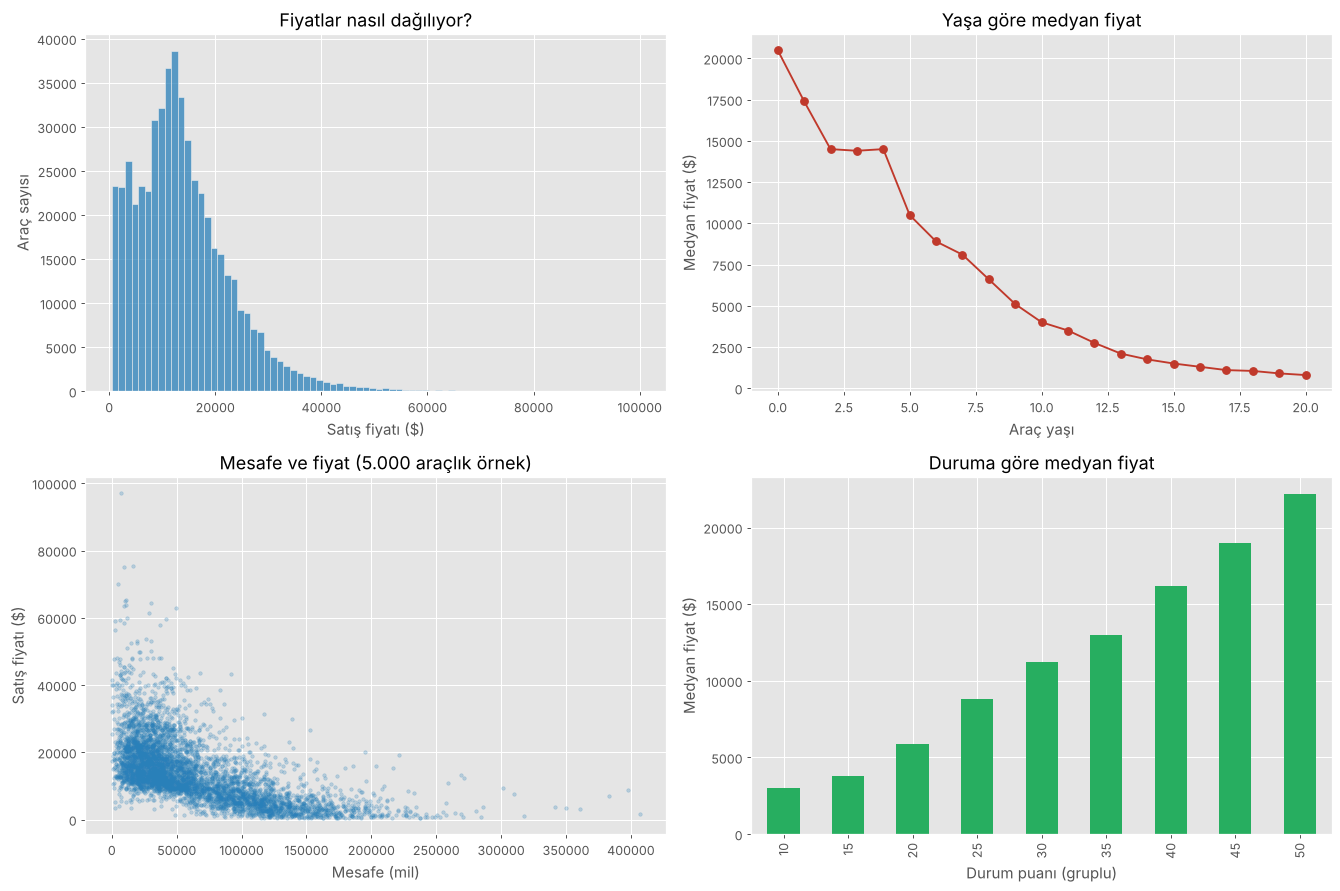

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(df['sellingprice'], bins=80, ax=ax[0, 0], color='#2980b9')
ax[0, 0].set_title('Fiyatlar nasıl dağılıyor?')
ax[0, 0].set_xlabel('Satış fiyatı ($)')
ax[0, 0].set_ylabel('Araç sayısı')

df.groupby('yas')['sellingprice'].median().loc[:20].plot(ax=ax[0, 1], marker='o', color='#c0392b')
ax[0, 1].set_title('Yaşa göre medyan fiyat')
ax[0, 1].set_xlabel('Araç yaşı')
ax[0, 1].set_ylabel('Medyan fiyat ($)')

ornek = df.sample(5000, random_state=42)
ax[1, 0].scatter(ornek['odometer'], ornek['sellingprice'], alpha=0.25, s=8, color='#2980b9')
ax[1, 0].set_title('Mesafe ve fiyat (5.000 araçlık örnek)')
ax[1, 0].set_xlabel('Mesafe (mil)')
ax[1, 0].set_ylabel('Satış fiyatı ($)')

df.groupby(((df['condition'] // 5) * 5).astype(int))['sellingprice'].median().plot(kind='bar', ax=ax[1, 1], color='#27ae60')
ax[1, 1].set_title('Duruma göre medyan fiyat')
ax[1, 1].set_xlabel('Durum puanı (gruplu)')
ax[1, 1].set_ylabel('Medyan fiyat ($)')

plt.tight_layout()
plt.show()

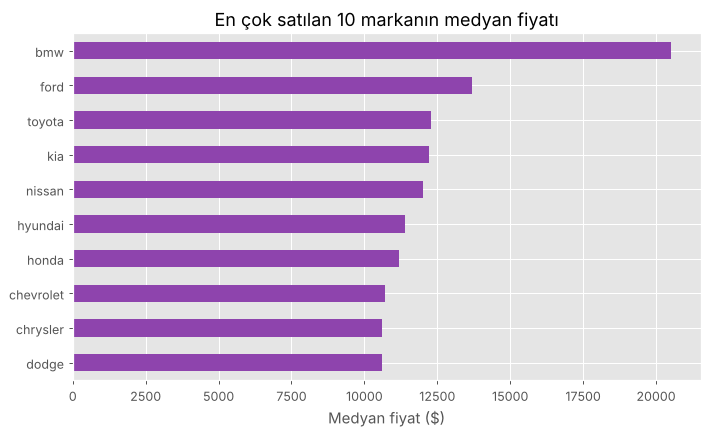

In [12]:
en_cok = df['make'].value_counts().head(10).index
(df[df['make'].isin(en_cok)]
   .groupby('make')['sellingprice'].median()
   .sort_values()
   .plot(kind='barh', figsize=(9, 5), color='#8e44ad', title='En çok satılan 10 markanın medyan fiyatı'))
plt.xlabel('Medyan fiyat ($)')
plt.ylabel('')
plt.show()

Grafiklerden çıkardıklarım:

- Fiyatların çoğu 5.000-20.000 $ arasında, sağa doğru uzayan bir dağılım var.
- Araç yaşlandıkça fiyat hızla düşüyor; ilk yıllarda düşüş daha sert.
- Mesafe arttıkça fiyat düşüyor ama ilişki düz bir çizgi değil.
- Durum puanı yükseldikçe fiyat net şekilde artıyor (4.3'teki düzeltme burada işe yaradı).
- Marka da fiyatı ciddi etkiliyor.

Bu ilişkilerin çoğu doğrusal değil. Bu yüzden ağaç tabanlı modellerin daha iyi çalışmasını bekliyorum.

## 7. Modele hazırlık

**Kullandığım bilgiler:** marka, model, donanım paketi, kasa tipi, vites, renk, iç döşeme, model yılı, yaş, mesafe, durum.

**Kullanmadıklarım:**
- `mmr`: Satıştan önce hesaplanmış piyasa değeri tahmini. Fiyatın neredeyse aynısı; modele verirsem fiyatı öğrenmek yerine bunu kopyalar.
- `vin`, `seller`, `state`, `saledate`: Aracın kendisiyle ilgili değil (şasi no, satıcı, eyalet, tarih). Tarihten yaşı zaten çıkardım.

Metin sütunlarını modelin anlayacağı sayılara çevirdim, sonra veriyi %80 eğitim, %20 test olarak ayırdım.

In [13]:
kategorik = ['make', 'model', 'trim', 'body', 'transmission', 'color', 'interior']
sayisal = ['year', 'yas', 'odometer', 'condition']

X = df[kategorik + sayisal].copy()
y = df['sellingprice']

kodlayici = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[kategorik] = kodlayici.fit_transform(X[kategorik])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Eğitim: {len(X_train):,} araç   Test: {len(X_test):,} araç')

Eğitim: 422,994 araç   Test: 105,749 araç


## 8. Modeller

Üç model denedim:

1. **Doğrusal Regresyon:** En basit model, karşılaştırma için.
2. **Random Forest:** Çok sayıda karar ağacının ortalamasını alıyor.
3. **Gradient Boosting:** Ağaçları sırayla kurup her seferinde bir öncekinin hatasını düzeltiyor (XGBoost'a benzer, scikit-learn içinde hazır geliyor).

İki ölçüye baktım: **R²** (fiyattaki farkların ne kadarını açıklıyor, 1'e ne kadar yakınsa o kadar iyi) ve **MAE** (tahmin gerçek fiyattan ortalama kaç dolar sapıyor).

### 8.1 Doğrusal Regresyon

Doğrusal model sayıya çevrilmiş kategorileri "büyüklük" sanacağı için ona markayı, kasayı, vitesi ve renkleri ayrı ayrı 0/1 sütunlarına çevirerek verdim.

In [14]:
X_lr = pd.get_dummies(df[['make', 'body', 'transmission', 'color', 'interior'] + sayisal],
                      columns=['make', 'body', 'transmission', 'color', 'interior'], dtype='uint8')
X_lr_train, X_lr_test = X_lr.loc[X_train.index], X_lr.loc[X_test.index]

lr = LinearRegression()
lr.fit(X_lr_train, y_train)
lr_tahmin = lr.predict(X_lr_test)
print(f'R²: {r2_score(y_test, lr_tahmin):.3f}   MAE: {mean_absolute_error(y_test, lr_tahmin):,.0f} $')

R²: 0.697   MAE: 3,504 $


### 8.2 Random Forest

In [15]:
rf = RandomForestRegressor(n_estimators=60, min_samples_leaf=3, max_features=0.6, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_tahmin = rf.predict(X_test)
print(f'R²: {r2_score(y_test, rf_tahmin):.3f}   MAE: {mean_absolute_error(y_test, rf_tahmin):,.0f} $')

R²: 0.953   MAE: 1,225 $


### 8.3 Gradient Boosting

In [16]:
gb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, max_leaf_nodes=63,
                                   categorical_features=[X.columns.get_loc(s) for s in ['make', 'body', 'transmission', 'color', 'interior']],
                                   random_state=42)
gb.fit(X_train, y_train)
gb_tahmin = gb.predict(X_test)
print(f'R²: {r2_score(y_test, gb_tahmin):.3f}   MAE: {mean_absolute_error(y_test, gb_tahmin):,.0f} $')

R²: 0.958   MAE: 1,199 $


### 8.4 Karşılaştırma

In [17]:
sonuclar = pd.DataFrame({
    'R²': [r2_score(y_test, t) for t in [lr_tahmin, rf_tahmin, gb_tahmin]],
    'MAE ($)': [mean_absolute_error(y_test, t) for t in [lr_tahmin, rf_tahmin, gb_tahmin]],
}, index=['Doğrusal Regresyon', 'Random Forest', 'Gradient Boosting']).sort_values('R²', ascending=False)
sonuclar.style.format({'R²': '{:.3f}', 'MAE ($)': '{:,.0f}'})

,R²,MAE ($)
Gradient Boosting,0.958,"1,199"
Random Forest,0.953,"1,225"
Doğrusal Regresyon,0.697,"3,504"


## 9. Model ezberliyor mu?

Eğitim verisindeki başarı test verisindekinden çok yüksekse model veriyi ezberlemiş demektir. En iyi modele baktım:

In [18]:
egitim = r2_score(y_train, gb.predict(X_train))
test = r2_score(y_test, gb_tahmin)
print(f'Eğitim R²: {egitim:.3f}')
print(f'Test R²  : {test:.3f}')
print(f'Fark     : {egitim - test:.3f}')

Eğitim R²: 0.965
Test R²  : 0.958
Fark     : 0.007


Fark çok küçük, yani model ezberlemiyor; daha önce görmediği araçlarda da aynı başarıyı gösteriyor.

## 10. Sonuçlara yakından bakış

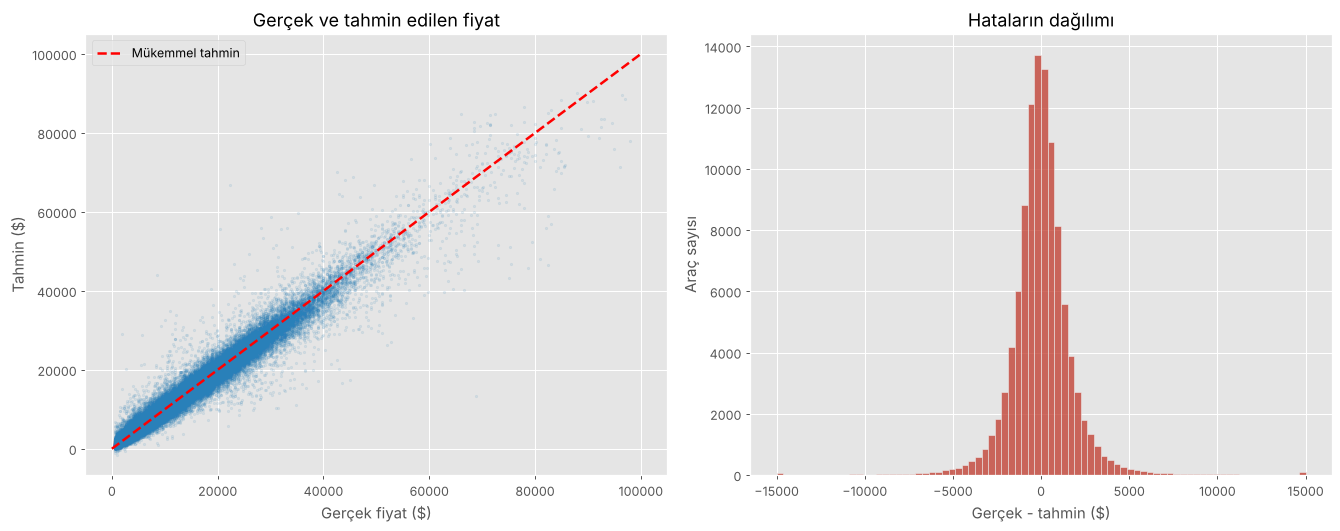

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].scatter(y_test, gb_tahmin, alpha=0.1, s=4, color='#2980b9')
ax[0].plot([0, 100_000], [0, 100_000], 'r--', lw=2, label='Mükemmel tahmin')
ax[0].set_title('Gerçek ve tahmin edilen fiyat')
ax[0].set_xlabel('Gerçek fiyat ($)')
ax[0].set_ylabel('Tahmin ($)')
ax[0].legend()

hata = y_test - gb_tahmin
sns.histplot(hata.clip(-15_000, 15_000), bins=80, ax=ax[1], color='#c0392b')
ax[1].set_ylabel('Araç sayısı')
ax[1].set_title('Hataların dağılımı')
ax[1].set_xlabel('Gerçek - tahmin ($)')

plt.tight_layout()
plt.show()

### Hangi fiyat aralığında daha çok yanılıyor?

In [20]:
aralik = pd.cut(y_test, bins=[0, 5_000, 10_000, 20_000, 30_000, 50_000, 100_000],
                labels=['0-5 bin', '5-10 bin', '10-20 bin', '20-30 bin', '30-50 bin', '50-100 bin'])
tablo = pd.DataFrame({'gercek': y_test, 'hata': (y_test - gb_tahmin).abs(), 'aralik': aralik})
ozet = tablo.groupby('aralik', observed=True).agg(arac_sayisi=('hata', 'size'), ortalama_hata=('hata', 'mean'),
                                                 ortalama_fiyat=('gercek', 'mean'))
ozet['hata_orani_%'] = ozet['ortalama_hata'] / ozet['ortalama_fiyat'] * 100
ozet.style.format({'arac_sayisi': '{:,}', 'ortalama_hata': '{:,.0f} $', 'ortalama_fiyat': '{:,.0f} $', 'hata_orani_%': '{:.1f}'})

,arac_sayisi,ortalama_hata,ortalama_fiyat,hata_orani_%
aralik,,,,
0-5 bin,"17,652",813 $,"2,797 $",29.0
5-10 bin,"20,883",991 $,"7,797 $",12.7
10-20 bin,"45,309","1,050 $","14,347 $",7.3
20-30 bin,"16,149","1,646 $","24,157 $",6.8
30-50 bin,"5,137","2,707 $","36,269 $",7.5
50-100 bin,619,"6,053 $","61,716 $",9.8


Dolar olarak pahalı araçlarda hata büyüyor, ama fiyata oranla bakınca 10-50 bin $ arasındaki araçlarda hata fiyatın yaklaşık %7'si; model en isabetli burada. En ucuz araçlarda oransal hata yüksek, çünkü 1.000 $'lık bir sapma 3.000 $'lık bir araçta büyük fark.

### Fiyatı en çok ne etkiliyor?

Random Forest her bilginin tahmine ne kadar katkı yaptığını gösterebiliyor:

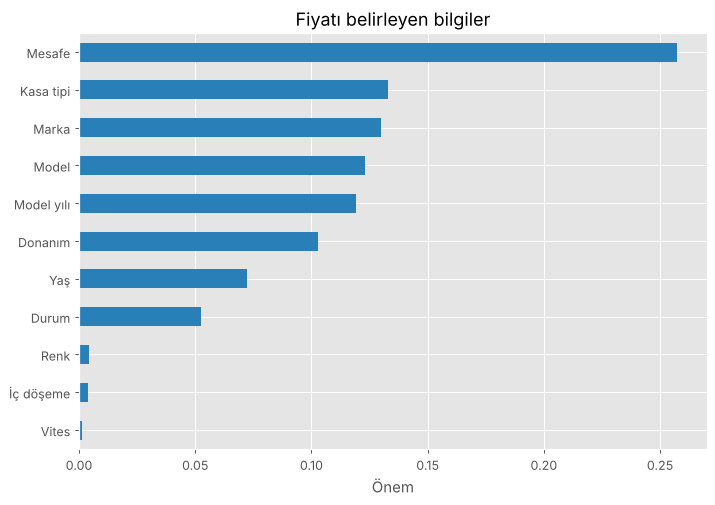

In [21]:
onem = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
isimler = {'make': 'Marka', 'model': 'Model', 'trim': 'Donanım', 'body': 'Kasa tipi', 'transmission': 'Vites',
           'color': 'Renk', 'interior': 'İç döşeme', 'year': 'Model yılı', 'yas': 'Yaş', 'odometer': 'Mesafe',
           'condition': 'Durum'}
onem.rename(isimler).plot(kind='barh', figsize=(9, 6), color='#2980b9', title='Fiyatı belirleyen bilgiler')
plt.xlabel('Önem')
plt.show()

## 11. Deneme: bir aracın fiyatını tahmin et

Modeli gerçekten kullanılabilir hale getirmek için küçük bir fonksiyon yazdım.

In [22]:
def fiyat_tahmin(marka, model, donanim, kasa, vites, renk, ic, yil, yas, mil, durum):
    arac = pd.DataFrame([[marka, model, donanim, kasa, vites, renk, ic, yil, yas, mil, durum]],
                        columns=kategorik + sayisal)
    arac[kategorik] = kodlayici.transform(arac[kategorik])
    return gb.predict(arac)[0]

ornekler = [
    ('toyota', 'camry', 'le', 'sedan', 'automatic', 'silver', 'gray', 2012, 3, 40_000, 40),
    ('toyota', 'camry', 'le', 'sedan', 'automatic', 'silver', 'gray', 2012, 3, 120_000, 20),
    ('ford', 'f-150', 'xlt', 'supercrew', 'automatic', 'white', 'gray', 2013, 1, 15_000, 45),
]
for o in ornekler:
    print(f'{o[7]} {o[0].title()} {o[1].title()}, {o[9]:,} mil, durum {o[10]}: yaklaşık {fiyat_tahmin(*o):,.0f} $')

2012 Toyota Camry, 40,000 mil, durum 40: yaklaşık 12,825 $
2012 Toyota Camry, 120,000 mil, durum 20: yaklaşık 7,913 $
2013 Ford F-150, 15,000 mil, durum 45: yaklaşık 26,149 $


Aynı Camry'nin mesafesi artıp durumu kötüleşince tahmin belirgin şekilde düşüyor; model beklediğimiz gibi davranıyor.

## 12. Sonuç

- **En iyi model Gradient Boosting:** R² %95,8, ortalama hata 1.199 $. Random Forest çok yakın (%95,3). Doğrusal Regresyon %69,7 ile geride kaldı, çünkü fiyatla özellikler arasındaki ilişkiler düz bir çizgi değil.
- **Fiyatı en çok etkileyenler:** mesafe, kasa tipi ve marka.
- **Temizlik önemliydi:** `condition` sütunundaki iki farklı ölçeği birleştirmek, durumun fiyatla ilişkisini belirgin şekilde güçlendirdi. Satış tarihinden çıkardığım araç yaşı da modele yeni bir bilgi kattı.
- **Model ezberlemiyor:** Eğitim ve test başarısı neredeyse aynı.

**Daha da geliştirmek için:** Eyalet bilgisini eklemek, 100.000 $ üstü lüks araçlar için ayrı bir model kurmak ve modelin ayarlarını (ağaç sayısı, derinlik) daha sistemli denemek.